# Talk to your data

You're an analyst. Someone drops a CSV on your desk with a fuzzy question attached: *which countries emit the most, what's the long-run trend, and can I see it?*

Normally that's an afternoon of pandas. Here you hand the agent the DataFrame and ask in prose — and by the end you'll have watched exactly how it answered.

## Setup

Install JAZ, provide an API key, and pick a model. Everything below runs in Colab — no local install.

In [1]:
%pip install -q jaz-lang

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, getpass

if not os.environ.get('OPENAI_API_KEY'):
    os.environ['OPENAI_API_KEY'] = getpass.getpass('OpenAI API key: ')

In [3]:
import jaz
from jaz.llm import LiteLLM

jaz.configure(llm=LiteLLM(model='openai/gpt-5.4-nano'))

## Load some real data

Global CO₂ emissions from [Our World in Data](https://github.com/owid/co2-data) — about 50,000 rows and 79 columns. The URL is pinned to a commit, so this notebook gives the same answer next year.

In [4]:
import pandas as pd

CO2_URL = (
    "https://raw.githubusercontent.com/owid/co2-data/"
    "382ee6c662b0ece26e111f263b44c029afad7787/owid-co2-data.csv"
)
co2 = pd.read_csv(CO2_URL)
print(f"{len(co2):,} rows x {len(co2.columns)} columns")
co2[["country", "year", "co2", "co2_per_capita"]].tail(3)

50,411 rows x 79 columns


,country,year,co2,co2_per_capita
50408,Zimbabwe,2022,12.232,0.761
50409,Zimbabwe,2023,13.443,0.823
50410,Zimbabwe,2024,13.701,0.824


## Hand the whole thing over

The DataFrame goes in as an ordinary keyword argument. No serialization, no chunking, no vector store — the agent gets the *actual object* and calls pandas on it.

`ReturnType` says what you want back. Ask for a dataclass and you get a real instance of it, with a DataFrame and a matplotlib figure inside — not text you have to parse.

Two details worth pausing on, because both follow from the same idea:

- **`Report` is passed twice** — once to `ReturnType`, which is how JAZ checks the result, and once as an ordinary input, which is how the agent gets the class to construct. `ReturnType` states the contract; it does not put the name in the agent's REPL.
- **`plt` is passed in too.** The agent's REPL cannot import anything. That is deliberate, and it means the libraries it may use are exactly the ones you hand it. Want it to plot? Give it the plotting library.

Your class and your libraries are inputs, the same as your data.

`ValidateReturn` runs your check *after* the agent returns. If an assertion fails, the message goes back to the agent and it tries again — so the contract covers the fields, not just the outer type.

The chart shows global total CO2 increasing from 5,930 in 1950 to 37,528 by 2022 (about +532.8%).


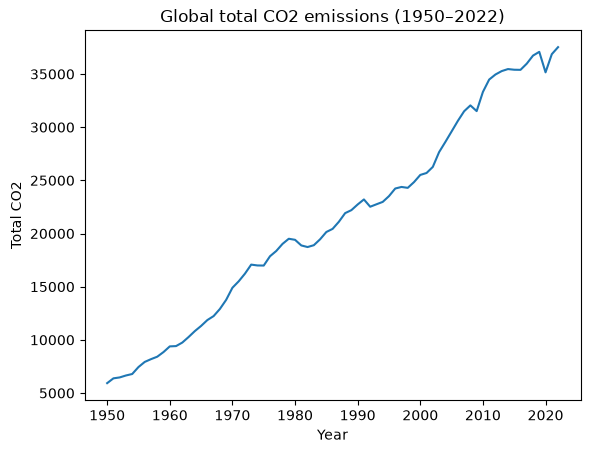

In [5]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
from matplotlib.figure import Figure

from jaz import invoke
from jaz.hooks import ReturnType, ValidateReturn


@dataclass
class Report:
    headline: str               # one sentence a human can read
    top_emitters: pd.DataFrame  # the ranking behind it
    trend: Figure               # a chart of the same story


def well_formed(report):
    """Checked after the agent returns. A failure sends it back to try again."""
    assert isinstance(report.headline, str) and report.headline.strip(), (
        "headline must be a non-empty sentence"
    )
    assert isinstance(report.top_emitters, pd.DataFrame), (
        f"top_emitters must be a DataFrame, got {type(report.top_emitters).__name__}"
    )
    assert len(report.top_emitters) == 8, (
        f"top_emitters must have 8 rows, got {len(report.top_emitters)}"
    )
    assert isinstance(report.trend, Figure), (
        f"trend must be a matplotlib Figure, got {type(report.trend).__name__}"
    )


report = invoke(
    ReturnType(Report),
    ValidateReturn(well_formed),
    task=(
        "Using the co2 DataFrame, for the year 2022: rank the top 8 countries by total "
        "co2 and put that DataFrame (columns: country, co2) in top_emitters. "
        "For trend, build a chart with fig, ax = plt.subplots(), plot global total co2 "
        "per year from 1950 to 2022 on ax, and put fig in the field. "
        "Summarise what the chart shows in headline. "
        "Fill in every field with a real value.\n"
        "The country column mixes real countries with aggregates like continents and "
        '"World" — aggregates have an empty iso_code, so exclude them when ranking.'
    ),
    co2=co2,
    Report=Report,
    plt=plt,
)
print(report.headline)

## What came back

`report` is a `Report`. Its fields are the objects you asked for, already typed — a DataFrame you can keep working with, and a real figure.

In [6]:
type(report.trend).__name__

'Figure'

In [7]:
report.top_emitters

,country,co2
0,China,11711.808
1,United States,5055.403
2,India,2831.132
3,Russia,1675.461
4,Japan,1029.645
5,Iran,767.178
6,Indonesia,758.021
7,Germany,667.843


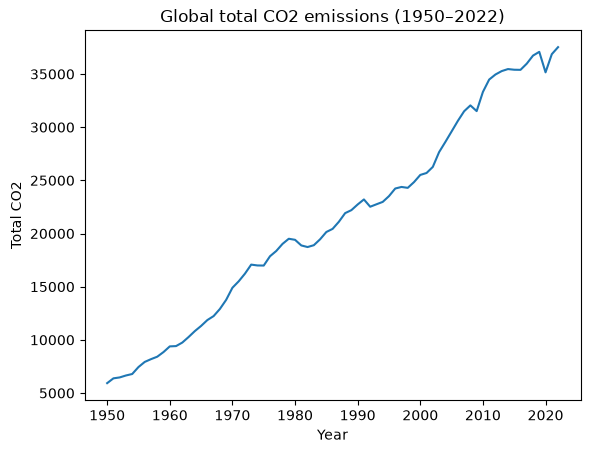

In [8]:
report.trend

## Now open the box

That's the payoff. Here's the part most frameworks hide: **the agent's answer *was* code.** Run any invoke inside a `PrintLogger` and you can read the whole loop — what the model was shown, the Python it wrote, what came back.

A small task this time so the trace stays short. `max_field_length` keeps the system prompt from flooding the output.

In [9]:
from jaz.hooks import PrintLogger

with PrintLogger(max_field_length=160):
    total = invoke(
        ReturnType(int),
        task="How many rows mention Brazil? Use the dataframe.",
        df=co2,
    )

total

2026-09-15 16:56:01 [Agent] invoke enter: inputs={'task': 'How many rows mention Brazil? Use the dataframe.', 'df':            country  year iso_code  population           gdp  cement_co2  \
0      Afghanistan...[truncated], depth=1, hooks=[PrintLogger(), ReturnType()]


2026-09-15 16:56:01 [Agent] invoke send: inputs={'task': 'How many rows mention Brazil? Use the dataframe.', 'df':            country  year iso_code  population           gdp  cement_co2  \
0      Afghanistan...[truncated], depth=1


2026-09-15 16:56:01 [Agent] message: {'role': 'system', 'content': 'You are in a multiturn REPL session.\n\n<response_format>\n- Respond with ONLY code. Your entire response will be sent verbatim to the REPL and executed as code.\n  Anything in your response that is not valid code is a syntax error.\n  - All natural language prose MUST be written as *comments* in your code.\n  - Do NOT wrap your code in markdown fences or XML tags.\n- Write a brief plan for your next step in comments on the first few lines of your response/code:\n\n    # <brief plan for next step>\n    code_for_next_step\n\n</response_format>\n\n<repl_spec>\n## Python REPL specification\n\n- Your response should contain Python code.\n- After the REPL executes your code, the printed output including any errors will be shown\n  to you in the next iteration. It is NOT shown to the caller.\n- Printed output will be truncated if it is too large.\n- The REPL state persists: if you assign a variable, it will be available in f

2026-09-15 16:56:01 [Agent] message: {'role': 'user', 'content': '<task type="str">\nHow many rows mention Brazil? Use the dataframe.\n</task>\n<df type="DataFrame">\n`df` [DataFrame]: Two-dimensional, size-mutable, potentially heterogeneous tabular data.\n  \n  Data structure also contains labeled axes (rows and columns).\n  Arithmetic operations align on both row and column labels. Can be\n  thought of as a dict-like container for Series objects. The primary\n  pandas data structure.\n  \n  Parameters\n  ----------\n  data : ndarray (structured or homogeneous), Iterable, dict, or DataFrame\n      Dict can contain Series, arrays, constants, dataclass or list-like objects. If\n      data is a dict, column order follows insertion-order. If a dict contains Series\n      which have an index defined, it is aligned by its index. This alignment also\n      occurs if data is a Series or a DataFrame itself. Alignment is done on\n      Series/DataFrame inputs.\n  \n      If data is a list of di

2026-09-15 16:56:01 [LLM] query enter: model=openai/gpt-5.4-nano, messages=2 messages


...

2026-09-15 16:56:03 [Agent] message: {'role': 'assistant', 'content': '# <brief plan for next step>\n# Count rows where any cell contains the substring "Brazil" (case-insensitive).\nmask = df.astype(str).apply(lambda row: row.str.contains("Brazil", case=False, na=False).any(), axis=1)\nreturn int(mask.sum())'}


2026-09-15 16:56:03 [Agent] repl iteration 0 input: code='# <brief plan for next step>\n# Count rows where any cell contains the substring "Brazil" (case-insensitive).\nmask = df.astype(str).apply(lambda row: row.str.contains("Brazil", case=False, na=False).any(), axis=1)\nreturn int(mask.sum())', depth=1


2026-09-15 16:56:09 [Agent] repl iteration 0 output: exec_result=Return(return_value=175), depth=1


2026-09-15 16:56:09 [Agent] invoke exit: result=Return(return_value=175), depth=1


175

## What you just watched

Three things happened in that trace, and they are the whole idea of JAZ:

1. **Your inputs were rendered into the prompt.** In the `user` message, `task` and `df` appear by name with their types. The model did not get a summary of your DataFrame — it got the DataFrame, plus a description of it.
2. **The model replied with Python, not prose.** The `assistant` message is executable code. There is nothing to parse out of it — the response *is* the program.
3. **It ran, and the agent saw the result.** `repl iteration 0 output` is what came back. Had it been wrong, the agent would have written another line and tried again.

See inputs → write code → read output → iterate. That loop is every JAZ agent.

---

**Next:** [Inputs and tools](02-inputs-and-tools.ipynb) — why your data, your tools and your prompt are the *same kind of thing*, and how to control what the model sees of each.